# Brac bank analysis

In [1]:
import camelot
import pandas as pd

In [2]:
pdf_path = "/home/aiml/workspace/CredirScoring/bank_statement_analysis/bank_statement_dataset/BRAC_Bank_Statement.pdf"
tables = camelot.read_pdf(pdf_path , flavor='stream' , pages=str(1),table_areas=['0,605,600,90'])


In [3]:
len(tables)

1

In [4]:
data =tables[0].df

In [ ]:
data

,0,1,2,3,4,5
0,DATE,PARTICULARS,CHQ.NO,WITHDRAW,DEPOSIT,BALANCE
1,,Balance Forward,,0.00,0.00,"194,308.04"
2,15-Aug-2024,PRCR/GENTLE PARK CHATT BD,,"4,180.00",,"190,128.04"
3,,/1056240310001,,,,
4,15-Aug-2024,DPS Installment to,,"7,000.00",,"183,128.04"
5,,3056240310001,,,,
6,19-Aug-2024,IB/BKASH/01878048591/NO,,"2,000.00",,"181,128.04"
7,,REMARKS,,,,
8,22-Aug-2024,CWDR/PRAGOTI SHORONI,,"5,015.00",,"176,113.04"
9,,"BRANCH , PR/1056240310001",,,,


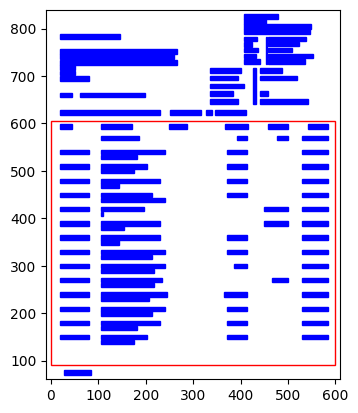

In [6]:
camelot.plot(tables[0], kind='contour').show()

In [7]:
new_header = data.iloc[0]
data = data[1:]
data.columns = new_header

In [ ]:
data

,DATE,PARTICULARS,CHQ.NO,WITHDRAW,DEPOSIT,BALANCE
1,,Balance Forward,,0.00,0.00,"194,308.04"
2,15-Aug-2024,PRCR/GENTLE PARK CHATT BD,,"4,180.00",,"190,128.04"
3,,/1056240310001,,,,
4,15-Aug-2024,DPS Installment to,,"7,000.00",,"183,128.04"
5,,3056240310001,,,,
6,19-Aug-2024,IB/BKASH/01878048591/NO,,"2,000.00",,"181,128.04"
7,,REMARKS,,,,
8,22-Aug-2024,CWDR/PRAGOTI SHORONI,,"5,015.00",,"176,113.04"
9,,"BRANCH , PR/1056240310001",,,,
10,22-Aug-2024,CRTR/MTB DHAKA BD,,,"40,000.00","216,113.04"


In [9]:
from datetime import datetime

def is_any_date_format(date_string):
    formats = [
        "%Y-%m-%d",         # 2024-08-15
        "%d-%m-%Y",         # 15-08-2024
        "%d-%b-%Y",         # 15-Aug-2024
        "%m/%d/%Y",         # 08/15/2024
        "%B %d, %Y",        # August 15, 2024
        "%d %B %Y",         # 15 August 2024
        # Add other formats as needed
    ]
    
    for date_format in formats:
        try:
            datetime.strptime(date_string, date_format)
            return True
        except ValueError:
            continue
    return False

In [ ]:
previous = 0
for index , row in data.iterrows():
    # print(type(row['DATE']))
    if row['DATE'] != "" and  is_any_date_format(row['DATE']):
        previous = index
    elif previous > 0:
        # print(data.loc[previous,"PARTICULARS"] + data.loc[index]["PARTICULARS"])
        data.loc[previous,"PARTICULARS"] = data.loc[previous,"PARTICULARS"] + data.loc[index]["PARTICULARS"]  
        data.drop(index=index, inplace=True) 


/tmp/ipykernel_21641/315045688.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[previous,"PARTICULARS"] = data.loc[previous,"PARTICULARS"] + data.loc[index]["PARTICULARS"]
/tmp/ipykernel_21641/315045688.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.drop(index=index, inplace=True)
/tmp/ipykernel_21641/315045688.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.loc[previous,"PARTICULARS"] = data.loc[previous

In [ ]:
data

,DATE,PARTICULARS,CHQ.NO,WITHDRAW,DEPOSIT,BALANCE
1,,Balance Forward,,0.00,0.00,"194,308.04"
2,15-Aug-2024,PRCR/GENTLE PARK CHATT BD/1056240310001,,"4,180.00",,"190,128.04"
4,15-Aug-2024,DPS Installment to3056240310001,,"7,000.00",,"183,128.04"
6,19-Aug-2024,IB/BKASH/01878048591/NOREMARKS,,"2,000.00",,"181,128.04"
8,22-Aug-2024,"CWDR/PRAGOTI SHORONIBRANCH , PR/1056240310001",,"5,015.00",,"176,113.04"
10,22-Aug-2024,CRTR/MTB DHAKA BD/,,,"40,000.00","216,113.04"
12,27-Aug-2024,CRTR/NPS ONLINE BANKINGTRNSFR G/,,,"27,000.00","243,113.04"
14,27-Aug-2024,IB/BKASH/01795531766/NOREMARKS,,"1,510.00",,"241,603.04"
16,31-Aug-2024,PRCR/SWING MAKEOVER SALONDHAKA /1056240310001,,"1,120.00",,"240,483.04"
18,31-Aug-2024,1056240310001:WTax Pd:01-08-2024 to 31-08-2024,,19.64,,"240,463.40"


# mtb analysis

In [12]:
from datetime import datetime

In [13]:
class preproccess():
    def __init__(self):
        pass

    def columns_name(self, data, page):
        columns = {}
        # for index , row in data.iterrows():
        len_columns =  len(data.columns)

        if page == 1:
            for index, row in  data.iterrows():
                if  "Opening Balance" not in row[2] :
                    if not columns:
                        for columns_index in range(len_columns):
                            columns[columns_index] = row[columns_index]
                    else:
                        for columns_index in range(len_columns):
                            columns[columns_index] = columns[columns_index] +" "+ row[columns_index]
                else:
                    return columns, index
        else:
            
            for index, row in  data.iterrows():
                # print(row)
                
                # print(data.loc[index+1,0])
                if self.is_any_date_format(data.loc[index+1,0]) and  (2 in columns and  'Transaction Details' in columns[2]) : # data.loc[index+1,2] == ""
                    # print(columns)
                    return columns, index
                else:
                    if not columns:
                        for columns_index in range(len_columns):
                            columns[columns_index] = row[columns_index]
                    else:
                        for columns_index in range(len_columns):
                            columns[columns_index] = columns[columns_index] +" "+ row[columns_index]
                
                    
            

    def is_any_date_format(self, date_string):
        formats = [
            "%Y-%m-%d",         # 2024-08-15
            "%d-%m-%Y",         # 15-08-2024
            "%d-%b-%Y",         # 15-Aug-2024
            "%m/%d/%Y",         # 08/15/2024
            "%B %d, %Y",        # August 15, 2024
            "%d %B %Y",         # 15 August 2024
            "%d/%m/%y %H:%M",   # 01/10/24 11:37
            # Add other formats as needed
        ]
        
        for date_format in formats:
            try:
                datetime.strptime(date_string, date_format)
                return True
            except ValueError:
                continue
        return False
    
    def plot(self, tables):
        camelot.plot(tables[0], kind='contour').show()


    def formating(self, tables, page ):
        
        data = tables[0].df
        columns_name , index = self.columns_name(data=data, page=page)
        # print(columns_name)
        data = data[index:]
        data.rename(columns=columns_name, inplace=True)
        data = data.reset_index(drop=True)
        # return data
        date_index = []
        for index , row in data.iterrows():
            if self.is_any_date_format(row[columns_name[0]]):
                date_index.append(index)
        # print(date_index)
                
        for i , index in enumerate(date_index):

            if i+1 == len(date_index) and  index < len(data)-1:
                temp = data.loc[index, columns_name[2]] 
                data.loc[index, columns_name[2]] = data.loc[index-1, columns_name[2]] + temp +data.loc[index+1, columns_name[2]]
            elif i+1 == len(date_index) and  index == len(data)-1:
                
                pass
            elif (abs(index - date_index[i+1])==3) or (abs(index - date_index[i+1]) ==2) and (abs(index - date_index[i-1]) ==3):
                temp = data.loc[index, columns_name[2]] 
                data.loc[index, columns_name[2]] = data.loc[index-1, columns_name[2]] + temp + data.loc[index+1, columns_name[2]]
            else:
              
              pass
        for index , row in data.iterrows():
            if index not in date_index:
                data.drop(index= index, inplace= True)
                       
        return data


    # def formating(self, table):
    #     data = table[0].df
    #     header = data.iloc[0]
    #     data = data[1:]
    #     data.columns = header

    #     previous = 0
    #     for index ,row in data.iterrows():
    #         print(row)
    #         if row['DATE'] != "" and  self.is_any_date_format(row['DATE']):
    #             previous = index
    #         elif previous > 0:
    #             data.loc[previous,"PARTICULARS"] = data.loc[previous,"PARTICULARS"] + data.loc[index]["PARTICULARS"]  
    #             data.drop(index=index, inplace=True) 
    #     return data


    
    


In [14]:
import camelot
import pandas as pd
from pypdf import PdfReader

In [15]:
pdf_path = "/home/aiml/workspace/CredirScoring/bank_statement_analysis/bank_statement_dataset/20241215125032.pdf"
reader = PdfReader(pdf_path)
page_count = len(reader.pages)
processing = preproccess()
final_data = pd.DataFrame()
dict_ = {1:['0,440,600,60'],
             2: ['0,750,600,30'],
             4: ['0,830,600,680']}

tables = camelot.read_pdf(pdf_path , flavor='stream' , pages=str(3),table_areas=dict_[2])
# processing.plot(tables=tables)
# df = processing.formating(tables=tables, page= 3)

data = pd.DataFrame()  # Initialize an empty DataFrame
changed_col ={}
columns_ = []
for page in range(1, page_count + 1):  # Loop from 1 to page_count (inclusive)
    if page > 1 and page != page_count:
        tables = camelot.read_pdf(pdf_path, flavor='stream', pages=str(page), table_areas=dict_[2])
        df = processing.formating(tables=tables, page=page)
        change_col = df.columns
        for now,  then in zip(change_col,columns_):
            changed_col[now] = then 
        df.rename(columns=changed_col, inplace=True)
        df = df.reset_index(drop=True)
        print(f"Shape of current DataFrame on page {page}: {df.shape}")  # Debugging step
        # data = pd.concat([data, df], axis=0, ignore_index=True)  # Append and reset index
    elif page == 1:
        tables = camelot.read_pdf(pdf_path, flavor='stream', pages=str(page), table_areas=dict_[1])
        df = processing.formating(tables=tables, page=page)
        df = df.reset_index(drop=True)
        columns_ = df.columns

        print(f"Shape of current DataFrame on page {page}: {df.shape}")  # Debugging step
    data = pd.concat([data, df], axis=0, ignore_index=True)  # Append and reset index

# Final DataFrame
print(f"Final concatenated DataFrame shape: {data.shape}")


/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)
/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)


Shape of current DataFrame on page 1: (13, 8)
Shape of current DataFrame on page 2: (25, 8)


/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)


Shape of current DataFrame on page 3: (25, 8)
Shape of current DataFrame on page 4: (25, 8)


/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)
/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)


...

/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)


Shape of current DataFrame on page 16: (25, 8)


/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)


Shape of current DataFrame on page 17: (25, 8)
Shape of current DataFrame on page 18: (25, 8)
Shape of current DataFrame on page 19: (3, 8)
Final concatenated DataFrame shape: (444, 8)


/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)
/tmp/ipykernel_21641/2576130023.py:71: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.rename(columns=columns_name, inplace=True)


In [16]:
data[data[' Transaction Details '] =='MB/BEFTN/1189051/1733405084538212/1311000947089/tr']

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch
420,05/12/24 13:24,05/12/24,MB/BEFTN/1189051/1733405084538212/131100094708...,,"200,000.00",0.00,"35,509.15",00001


In [ ]:
data.columns

Index(['Trans Date and  Time', 'Value  Date', ' Transaction Details ',
       'Ref/Cheque  No', ' Withdrawal (Dr.) ', ' Deposit (Cr.) ', ' Balance ',
       ' Tran Brch '],
      dtype='object')

In [ ]:
data[' Transaction Details '].isna().sum()

0

In [19]:
def parse_date(date_str):
    try:
        # Try the primary format
        return pd.to_datetime(date_str, format="%d/%m/%y %H:%M")
    except:
        try:
            # Try a fallback format if the primary fails
            return pd.to_datetime(date_str, format="%Y-%m-%d %H:%M:%S")
        except:
            return pd.NaT  # Return NaT if all formats fail:

In [20]:
data['Trans Date and  Time'] = data['Trans Date and  Time'].apply(parse_date)
# data['Value  Date'] = data['Value  Date'].apply(parse_date)


In [ ]:
data

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch
0,2023-12-28 18:27:00,28/12/23,Salary,,0.00,"45,507.00","45,507.00",00003
1,2023-12-28 18:57:00,28/12/23,CW-Palmal Tower RATM-336212564675-556764-303506,,"2,000.00",0.00,"43,507.00",00099
2,2023-12-28 18:57:00,28/12/23,CW-Palmal Tower RATM-336212564675-556764-303506,,13.04,0.00,"43,493.96",00099
3,2023-12-28 18:57:00,28/12/23,CW-Palmal Tower RATM-336212564675-556764-303506,,1.96,0.00,"43,492.00",00099
4,2023-12-29 11:31:00,29/12/23,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,"5,000.00",0.00,"38,492.00",00099
...,...,...,...,...,...,...,...,...
439,2024-12-15 11:23:00,15/12/24,MB/bKash/4714670/1734261827317536/bkash,,"2,000.00",0.00,"22,192.15",00001
440,2024-12-15 12:40:00,15/12/24,MB/FT/12241559/1311001294916/1311000947089/,,0.00,100.00,"22,292.15",00001
441,2024-12-15 11:20:00,15/12/24,MB/FT/12239583/1311000947089/0030310092402/,,"2,000.00",0.00,"24,192.15",00001
442,2024-12-15 11:23:00,15/12/24,MB/bKash/4714670/1734261827317536/bkash,,"2,000.00",0.00,"22,192.15",00001


In [ ]:
data[data['Trans Date and  Time'] == '2023-12-31 17:46:00']#[' Transaction Details ']

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch
11,2023-12-31 17:46:00,31/12/23,CW-(TBdoA267) Mohakha-336511319355-704339-390989,,"3,000.00",0.00,"28,759.00",00099
12,2023-12-31 17:46:00,31/12/23,CW-(TBdoA267) Mohakha-336511319355-704339-390989,,13.04,0.00,"28,745.96",00099
13,2023-12-31 17:46:00,31/12/23,,,1.96,0.00,"28,744.00",00099


## Negative truggers
- Equal credits and debits

# 1. Income verification 
- Regular Income

In [23]:
data.columns

Index(['Trans Date and  Time', 'Value  Date', ' Transaction Details ',
       'Ref/Cheque  No', ' Withdrawal (Dr.) ', ' Deposit (Cr.) ', ' Balance ',
       ' Tran Brch '],
      dtype='object')

In [24]:
data.dtypes

Trans Date and  Time     datetime64[ns]
Value  Date                      object
 Transaction Details             object
Ref/Cheque  No                   object
 Withdrawal (Dr.)                object
 Deposit (Cr.)                   object
 Balance                         object
 Tran Brch                       object
dtype: object

In [25]:

# data[' Deposit (Cr.) '] = data[' Deposit (Cr.) '].astype(float)
def remove_comma(amount):
    amount = float(amount.replace(",",""))
    return amount
data[' Deposit (Cr.) '] = data[' Deposit (Cr.) '].apply(remove_comma)


In [26]:
credit_transaction =  data[data[' Deposit (Cr.) '] > 0.00]

In [134]:
credit_transaction.loc[299][' Transaction Details '] #'REV/MB/bKash/4672848/1733679411198876/bkash'


'REV/MB/IBFT/6907359/0076100000022/1311000947089/np'

In [28]:
salary_keywords = ['SALARY', 'PAYROLL', 'WAGE', 'INCOME', 'PAY']
credit_transaction['is_salary'] = credit_transaction[' Transaction Details '].str.contains(
    '|'.join(salary_keywords), case=False, na=False
)


/tmp/ipykernel_21641/3318962815.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  credit_transaction['is_salary'] = credit_transaction[' Transaction Details '].str.contains(


In [29]:
regular_income = credit_transaction[credit_transaction['is_salary']]
credit_transaction['Trans Date and  Time'] = pd.to_datetime(credit_transaction['Trans Date and  Time'])
regular_income['Trans Date and  Time'] = pd.to_datetime(regular_income['Trans Date and  Time']) # 'Value  Date'
regular_income['Value  Date'] = pd.to_datetime(regular_income['Value  Date']) # 'Value  Date'

/tmp/ipykernel_21641/174557327.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  credit_transaction['Trans Date and  Time'] = pd.to_datetime(credit_transaction['Trans Date and  Time'])
/tmp/ipykernel_21641/174557327.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  regular_income['Trans Date and  Time'] = pd.to_datetime(regular_income['Trans Date and  Time']) # 'Value  Date'
/tmp/ipykernel_21641/174557327.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling bac

In [ ]:
regular_income = regular_income.sort_values(by='Value  Date')
regular_income

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch,is_salary
0,2023-12-28 18:27:00,2023-12-28,Salary,,0.00,45507.0,"45,507.00",00003,True
35,2024-01-17 14:09:00,2024-01-17,Salary M/O-December-2023,,0.00,73007.0,"84,040.84",00003,True
87,2024-02-15 15:44:00,2024-02-15,SALARY jan 24,,0.00,74347.0,"90,235.72",00003,True
165,2024-04-18 13:14:00,2024-04-18,Staffs Salary M/O-March-2024,,0.00,74347.0,"162,856.30",00003,True
189,2024-05-19 11:56:00,2024-05-19,Staffs Salary M/O-April-2024,,0.00,74347.0,"194,040.13",00003,True
336,2024-10-06 11:18:00,2024-06-10,Staffs Salary M/O-September- 2024,,0.00,74275.0,"283,382.99",00003,True
210,2024-06-13 16:16:00,2024-06-13,Staffs Salary M/O-May-2024,,0.00,74347.0,"269,178.88",00003,True
246,2024-07-16 15:47:00,2024-07-16,SALARY JUNE 24,,0.00,74347.0,"271,088.63",00003,True
285,2024-08-21 12:58:00,2024-08-21,Staffs Salary M/O-July-2024,,0.00,74275.0,"296,442.09",00003,True
306,2024-09-11 16:09:00,2024-11-09,Staffs Salary M/O-August-202 4,,0.00,74275.0,"267,463.99",00003,True


In [31]:
regular_income['Interval'] = regular_income['Value  Date'].diff().dt.days


In [32]:
regular_income_summary = regular_income.groupby(regular_income['Value  Date'].dt.to_period('M'))[' Deposit (Cr.) '].sum()


In [ ]:
regular_income_summary.mean()

86169.6

In [ ]:
regular_income_summary.std()

34089.21059416503

# Expenses
- recurring expenses
- expenses pattren 

In [35]:
categories = {
    'Rent': ['RENT', 'LEASE'],
    'Mobile': ['MOBILE'],
    'Utilities': ['BAKHRABAD','PASCHIMANCHAL','KARNAPHULI','JALALABAD', 'BTCL','DPDC','DESCO','NSDA','WASA','NESCO','WATER', 'UTILITY', 'GAS', 'POWER'],
    'Loan Payments': ['CRCARD','CREDIT CARD','PAYMEMENT', 'EMI', 'MORTGAGE', 'CAR LOAN'],
    'Subscriptions': ['NETFLIX', 'SPOTIFY', 'SUBSCRIPTION', 'HULU'],
    'Groceries': ['SUPERMARKET', 'GROCERY', 'STORE'],
    'Savings' : ["STANDING INSTRUCTION", "FD"]
}

In [36]:
# Assign categories based on description keywords
def categorize_transaction(description):
    for category, keywords in categories.items():
        if any(keyword in description.upper() for keyword in keywords):
            return category
    return 'Other'

In [37]:
data[' Withdrawal (Dr.) '] = data[' Withdrawal (Dr.) '].apply(remove_comma)


In [ ]:
expences = data[data[' Withdrawal (Dr.) '] > 0]
# data["expences category"] = 
expences['category'] = expences[' Transaction Details '].apply(categorize_transaction)
expences['Trans Date and  Time'] = pd.to_datetime(expences['Trans Date and  Time'])

/tmp/ipykernel_21641/3244763799.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  expences['category'] = expences[' Transaction Details '].apply(categorize_transaction)
/tmp/ipykernel_21641/3244763799.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  expences['Trans Date and  Time'] = pd.to_datetime(expences['Trans Date and  Time'])


In [39]:
monthly_expenses = expences.groupby([expences['Trans Date and  Time'].dt.to_period('M'), 'category'])[' Withdrawal (Dr.) '].sum().unstack()


In [40]:
monthly_expenses

category,Loan Payments,Mobile,Other,Savings
Trans Date and Time,,,,
2023-12,NaN,NaN,16913.00,NaN
2024-01,13423.16,570.0,56593.00,NaN
2024-02,8261.12,200.0,43251.00,NaN
2024-03,4579.19,NaN,55739.00,NaN
2024-04,1054.23,NaN,34392.00,NaN
2024-05,6030.17,NaN,35608.00,NaN
2024-06,10540.25,NaN,59266.00,NaN
2024-07,NaN,643.0,160532.88,NaN
2024-08,2470.91,1168.0,250602.00,10000.0


In [ ]:
expences[expences['category']=='Savings'][' Withdrawal (Dr.) '].mean()

10000.0

In [ ]:
expences.groupby(expences['category'])[' Withdrawal (Dr.) '].sum()

category
Loan Payments      82950.47
Mobile              2631.00
Other            1528598.38
Savings            40000.00
Name:  Withdrawal (Dr.) , dtype: float64

# total credit and debit 

In [43]:
total_expences= data[[' Withdrawal (Dr.) ']].sum().values[0]

In [44]:
total_income = data[[' Deposit (Cr.) ']].sum().values[0]

# savings 

In [ ]:
total_savings = total_income - total_expences
total_savings

18392.149999999907

In [ ]:
data

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch
0,2023-12-28 18:27:00,28/12/23,Salary,,0.00,45507.0,"45,507.00",00003
1,2023-12-28 18:57:00,28/12/23,CW-Palmal Tower RATM-336212564675-556764-303506,,2000.00,0.0,"43,507.00",00099
2,2023-12-28 18:57:00,28/12/23,CW-Palmal Tower RATM-336212564675-556764-303506,,13.04,0.0,"43,493.96",00099
3,2023-12-28 18:57:00,28/12/23,CW-Palmal Tower RATM-336212564675-556764-303506,,1.96,0.0,"43,492.00",00099
4,2023-12-29 11:31:00,29/12/23,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,5000.00,0.0,"38,492.00",00099
...,...,...,...,...,...,...,...,...
439,2024-12-15 11:23:00,15/12/24,MB/bKash/4714670/1734261827317536/bkash,,2000.00,0.0,"22,192.15",00001
440,2024-12-15 12:40:00,15/12/24,MB/FT/12241559/1311001294916/1311000947089/,,0.00,100.0,"22,292.15",00001
441,2024-12-15 11:20:00,15/12/24,MB/FT/12239583/1311000947089/0030310092402/,,2000.00,0.0,"24,192.15",00001
442,2024-12-15 11:23:00,15/12/24,MB/bKash/4714670/1734261827317536/bkash,,2000.00,0.0,"22,192.15",00001


In [ ]:
# Ensure datetime conversion and set index
data['Trans Date and Time'] = pd.to_datetime(data['Trans Date and  Time'])  # Fix the column name if needed
data.set_index('Trans Date and Time', inplace=True)

# Clean column names
data.columns = data.columns.str.strip()

# Group by month
monthly_data_withdrawal = data.groupby(pd.Grouper(freq='M'))['Withdrawal (Dr.)'].sum()


# Display the result


/tmp/ipykernel_21641/4047548060.py:9: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_data_withdrawal = data.groupby(pd.Grouper(freq='M'))['Withdrawal (Dr.)'].sum()


In [48]:
monthly_data_income = data.groupby(pd.Grouper(freq='M'))['Deposit (Cr.)'].sum()


/tmp/ipykernel_21641/3656902372.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_data_income = data.groupby(pd.Grouper(freq='M'))['Deposit (Cr.)'].sum()


In [49]:
monthyly_savings =  monthly_data_income - monthly_data_withdrawal

In [ ]:
monthyly_savings

Trans Date and Time
2023-12-31     28594.00
2024-01-31     10460.84
2024-02-29     22934.88
2024-03-31     34028.81
2024-04-30     59837.77
2024-05-31     42708.83
2024-06-30     99852.75
2024-07-31    -23741.88
2024-08-31    -74965.91
2024-09-30     26423.90
2024-10-31    -27195.88
2024-11-30     11977.04
2024-12-31   -192523.00
Freq: ME, dtype: float64

# equal debit and credit 

In [ ]:
data.columns

Index(['Trans Date and  Time', 'Value  Date', 'Transaction Details',
       'Ref/Cheque  No', 'Withdrawal (Dr.)', 'Deposit (Cr.)', 'Balance',
       'Tran Brch'],
      dtype='object')

In [ ]:
data['Value  Date'] = pd.to_datetime(data['Value  Date'])

import pandas as pd

def detect_matching_pairs(df):
    # Store matching pairs
    matching_days = {'date': [], 'data': []}

    # Iterate through each date group
    for date, group in df.groupby(df['Value  Date'].dt.date):
        # Separate credits and debits
        credits = group[group['Deposit (Cr.)'] > 0]
        debits = group[group['Withdrawal (Dr.)'] > 0]

        # Extract values as lists
        credit_values = credits['Deposit (Cr.)'].values.tolist()
        debit_values = debits['Withdrawal (Dr.)'].values.tolist()

        # Match credits and debits
        for credit in credit_values:
            if credit in debit_values:
                # Record the matching pair
                matching_days['date'].append(date)
                matching_days['data'].append(credit)

                # Remove the matched credit and debit from the DataFrame
                credit_index = credits[credits['Deposit (Cr.)'] == credit].index[0]
                debit_index = debits[debits['Withdrawal (Dr.)'] == credit].index[0]

                df.drop([credit_index, debit_index], inplace=True)

                # Remove the matched value to avoid duplicate matches
                debit_values.remove(credit)

    # Return matching pairs
    return matching_days, df



/tmp/ipykernel_21641/2623898507.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data['Value  Date'] = pd.to_datetime(data['Value  Date'])


In [53]:
matching_days , data = detect_matching_pairs(data)

# Bank statement analysis
    1. transaction volumn 
        a. Trend in monthly credits over a 6 month period
        b.  Percentage of cash deposits
    2. Non recurring transactions
        a. Non recurring credits
        b. Non recurring debits
    3. Loan Obligations
        a. Number of loans owned by the borrower
        b. Loan Amount Applied / Total Inflows
        c. Loan Repayments /Total Inflows
        d. Loan Repayments / Total Outflows
    4. Cashflow indicators
        a. Share of Positive Cash Flow
        b. Estimated Income / Declared Amount
    5. Negative triggers
        a. Cheques bounced / returned
        b. Biz EOD Balances
        c. Equal Credits and Debits
        

### 1. a) Trend in monthly credits over a 6 month period

Here are some common ways to define and classify trends:

a) Percentage Change: 
- Measures the relative change between two consecutive data points.
     Percentage Change = ((New Value − Old Value)/Old Value)×100

- A consistent increase in percentage change suggests an upward trend, while consistent decreases suggest a downward trend.

b) Slope of the Trend
- The slope from a linear regression line indicates the overall direction of the data:

    - A positive slope: Upward trend.
    - A negative slope: Downward trend.
    - A slope near zero: Stable trend.
            𝑦 =𝑚𝑥+𝑏

        𝑚: The slope (rate of change).

        𝑏: The intercept.

c) Moving Averages

- Moving averages smooth the data by calculating the average of values within a specific window (e.g., 3 months).
- A rising moving average: Upward trend.
- A falling moving average: Downward trend.

d) Volatility

- Volatility measures how much the data fluctuates. High volatility suggests instability, while low volatility suggests consistency.
- Measured using the standard deviation of changes.

### Automated Trend Detection Process
To automate trend detection, follow these steps:

- Step 1: Calculate Key Metrics

    - Compute the percentage change and observe whether values are mostly positive or negative.
    - Perform linear regression to find the slope of the trend line.
    - Compute a moving average to smooth out short-term noise.
    - Measure volatility using standard deviation.

- Step 2: Apply Rules to Define Trends

    - Based on the calculated metrics, use rules to classify the trend:

        - Upward Trend: Positive slope, increasing moving average, and positive percentage change.
        - Downward Trend: Negative slope, decreasing moving average, and negative percentage change.
        - Stable Trend: Near-zero slope, consistent moving average, and low volatility.
        - Volatile Trend: High volatility with no consistent direction.

- Step 3: Report and Visualize

    - Present the trend type alongside the data and visualizations (e.g., line plots or bar charts).
    - Visuals make it easier to confirm trends identified by metrics.

In [54]:
df = data.copy()

In [55]:
df['Trans Date and  Time'].isna().sum()

0

In [56]:
def parse_date(date_str):
    try:
        # Try the primary format
        return pd.to_datetime(date_str, format="%d/%m/%y %H:%M")
    except:
        try:
            # Try a fallback format if the primary fails
            return pd.to_datetime(date_str, format="%Y-%m-%d %H:%M:%S")
        except:
            return pd.NaT  # Return NaT if all formats fail

In [57]:
# Apply parsing function
df['Trans Date and  Time'] = df['Trans Date and  Time'].apply(parse_date)

In [58]:
# df['Trans Date and Time'] = df['Trans Date and Time'].fillna(pd.to_datetime(df['Date'], errors='coerce'))
df['Month'] = df['Trans Date and  Time'].dt.to_period('M')

In [59]:
last_6_months = pd.Timestamp.now().to_period('M') - pd.offsets.MonthEnd(6)
filtered_df = df[df['Month'] > last_6_months]

In [60]:
# filtered_df[filtered_df['Month'] == "2024-11"]

In [61]:
# Group by month and sum the credits
# monthly_credits = last_six_months.groupby(last_six_months['Trans Date and  Time'].dt.to_period('M'))[' Deposit (Cr.) '].sum()
# monthly_credits = filtered_df.groupby('Month')[['Month',' Transaction Details ',' Deposit (Cr.) ']].apply(lambda x: x.values.tolist())
monthly_credits = filtered_df.groupby('Month')[['Deposit (Cr.)']].sum()


In [62]:
monthly_credits

,Deposit (Cr.)
Month,
2024-08,89275.0
2024-09,74275.0
2024-10,88275.0
2024-11,88275.0
2024-12,29200.0


In [63]:
monthly_credits['Pct_Change'] = monthly_credits['Deposit (Cr.)'].pct_change() * 100


In [64]:
from sklearn.linear_model import LinearRegression
import numpy as np

In [65]:
# 1. Calculate Slope (Linear Regression)
X = np.arange(len(monthly_credits)).reshape(-1, 1)  # Time indices
y = monthly_credits['Deposit (Cr.)']
model = LinearRegression()
model.fit(X, y)
slope = model.coef_[0]

In [66]:
# 2. Calculate Moving Average
monthly_credits['Moving_Avg'] = monthly_credits['Deposit (Cr.)'].rolling(window=3).mean()

In [67]:
# 3. Calculate Volatility (Standard Deviation of % Change)
volatility = monthly_credits['Pct_Change'].std()

In [68]:
# Define Trend Based on Metrics
if slope > 0 and monthly_credits['Pct_Change'].mean() > 0:
    trend = "Upward Trend"
elif slope < 0 and monthly_credits['Pct_Change'].mean() < 0:
    trend = "Downward Trend"
elif abs(slope) < 0.01 and volatility < 10:
    trend = "Stable Trend"
else:
    trend = "Volatile Trend"

In [69]:
# Print Results
print("Slope:", slope)
print("Volatility:", volatility)
print("Trend Detected:", trend)

Slope: -10615.000000000002
Volatility: 36.805345271320185
Trend Detected: Downward Trend


## b. Percentage of cash deposits

In [70]:
data.columns

Index(['Trans Date and  Time', 'Value  Date', 'Transaction Details',
       'Ref/Cheque  No', 'Withdrawal (Dr.)', 'Deposit (Cr.)', 'Balance',
       'Tran Brch'],
      dtype='object')

In [71]:
deposit = data[data['Deposit (Cr.)'] > 0.0]

In [72]:
cash_keywords = ['CAD']
deposit['cash_deposit'] = deposit['Transaction Details'].str.contains(
    '|'.join(cash_keywords), case=False, na=False
)

/tmp/ipykernel_21641/2394327700.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  deposit['cash_deposit'] = deposit['Transaction Details'].str.contains(


In [73]:
total_cash_deposit =  deposit[deposit['cash_deposit'] == True]['Deposit (Cr.)'].values[0]
total_inflows = deposit['Deposit (Cr.)'].sum()
percentage_cash_deposit =  (total_cash_deposit/total_inflows)/100

In [74]:

print(f"{percentage_cash_deposit:.20f}")

0.00002605390204948678


  2. Non recurring transactions    
     
    - Non recurring credits
    - Non recurring debits

In [75]:
data.head(50)

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch
Trans Date and Time,,,,,,,,
2023-12-28 18:27:00,2023-12-28 18:27:00,2023-12-28,Salary,,0.00,45507.0,"45,507.00",00003
2023-12-28 18:57:00,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,2000.00,0.0,"43,507.00",00099
2023-12-28 18:57:00,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,13.04,0.0,"43,493.96",00099
2023-12-28 18:57:00,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,1.96,0.0,"43,492.00",00099
2023-12-29 11:31:00,2023-12-29 11:31:00,2023-12-29,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,5000.00,0.0,"38,492.00",00099
2023-12-29 11:31:00,2023-12-29 11:31:00,2023-12-29,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,13.04,0.0,"38,478.96",00099
2023-12-29 11:31:00,2023-12-29 11:31:00,2023-12-29,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,1.96,0.0,"38,477.00",00099
2023-12-29 11:32:00,2023-12-29 11:32:00,2023-12-29,POS-SHWAPNO - SATERKUL-336305606907-582542-319012,,388.00,0.0,"38,089.00",00099
2023-12-29 11:53:00,2023-12-29 11:53:00,2023-12-29,MB/BDT/541487%0720/9120500200011756/1311000947089,,5000.00,0.0,"33,089.00",00001


In [76]:
import re 

In [77]:
df =data.copy()

In [78]:
# Normalize the description
def normalize_description(description):
    description = description.lower().strip()  # Convert to lowercase
    # description = re.sub(r'\d+', '', description)  # Remove numbers
    # description = re.sub(r'[^\w\s]', '', description)  # Remove special characters
    description = re.sub(r'\s+', ' ', description)  # Remove extra spaces
    return description


In [79]:
df.columns

Index(['Trans Date and  Time', 'Value  Date', 'Transaction Details',
       'Ref/Cheque  No', 'Withdrawal (Dr.)', 'Deposit (Cr.)', 'Balance',
       'Tran Brch'],
      dtype='object')

In [80]:
df['normalize_description'] = df['Transaction Details'].apply(normalize_description)

In [81]:
df

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch,normalize_description
Trans Date and Time,,,,,,,,,
2023-12-28 18:27:00,2023-12-28 18:27:00,2023-12-28,Salary,,0.00,45507.0,"45,507.00",00003,salary
2023-12-28 18:57:00,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,2000.00,0.0,"43,507.00",00099,cw-palmal tower ratm-336212564675-556764-303506
2023-12-28 18:57:00,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,13.04,0.0,"43,493.96",00099,cw-palmal tower ratm-336212564675-556764-303506
2023-12-28 18:57:00,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,1.96,0.0,"43,492.00",00099,cw-palmal tower ratm-336212564675-556764-303506
2023-12-29 11:31:00,2023-12-29 11:31:00,2023-12-29,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,5000.00,0.0,"38,492.00",00099,cw-satarkul branch at-336304606518-581737-318479
...,...,...,...,...,...,...,...,...,...
2024-12-14 18:45:00,2024-12-14 18:45:00,2024-12-14,MB/bKash/4711443/1734201930951110/bkash,,500.00,0.0,"24,192.15",00001,mb/bkash/4711443/1734201930951110/bkash
2024-12-15 11:23:00,2024-12-15 11:23:00,2024-12-15,MB/bKash/4714670/1734261827317536/bkash,,2000.00,0.0,"22,192.15",00001,mb/bkash/4714670/1734261827317536/bkash
2024-12-15 12:40:00,2024-12-15 12:40:00,2024-12-15,MB/FT/12241559/1311001294916/1311000947089/,,0.00,100.0,"22,292.15",00001,mb/ft/12241559/1311001294916/1311000947089/


In [82]:
from sentence_transformers import SentenceTransformer

# Load a pre-trained embedding model
model = SentenceTransformer('all-MiniLM-L6-v2')
debit = df[df['Withdrawal (Dr.)'] > 0].reset_index(drop=True)
credit = df[df['Deposit (Cr.)'] >0].reset_index(drop=True)
# Generate embeddings for transaction descriptions
embeddings = model.encode(credit['normalize_description'].tolist())


/home/aiml/workspace/CredirScoring/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [83]:
from sklearn.cluster import DBSCAN
import numpy as np

# Convert embeddings to a numpy array
embeddings = np.array(embeddings)

# Perform clustering (DBSCAN is density-based and does not require specifying the number of clusters)
dbscan = DBSCAN(eps=0.5, min_samples=2, metric='cosine')
credit['Cluster'] = dbscan.fit_predict(embeddings)


In [84]:
# Group descriptions by clusters
clusters = credit.groupby('Cluster')['normalize_description'].apply(list)

# Print clusters
for cluster, descriptions in clusters.items():
    print(f"Cluster {cluster}:")
    print(descriptions)


Cluster -1:
['festival allowance 2024', 'bonus 2024']
Cluster 0:
['salary', 'salary m/o-december-2023', 'salary jan 24', 'staffs salary m/o-february-2 024', 'staffs salary m/o-march-2024', 'staffs salary m/o-april-2024', 'staffs salary m/o-may-2024', 'salary june 24', 'staffs salary m/o-july-2024', 'staffs salary m/o-august-202 4', 'staffs salary m/o-september- 2024', 'staffs salary m/o-october-20 24']
Cluster 1:
['npsb ibft-140124283652-00001311000947089-nps onli', 'npsb ibft-060262102534-00001311000947089-ific ban', 'npsb ibft-417700526029-00001311000947089-citytouc', 'npsb ibft-417700533049-00001311000947089-citytouc', 'npsb ibft-418600346850-00001311000947089-citytouc', 'cad-mtb dhanmondi bran-000247492583-345315-703142', 'npsb ibft-430516616436-00001311000947089-brbl onl', 'npsb ibft-431617185572-00001311000947089-brbl onl']
Cluster 2:
['mb/ft/7698784/1311001294916/1311000947089/hihj', 'mb/ft/8051621/1311001686083/1311000947089/debt p', 'mb/ft/9007996/1311001686083/1311000947089/d

In [ ]:
def get_cluster_name(cluster_texts, top_n=1):
    # Define keywords and labels
    keywords = {
        'bonus': ['allowance', 'bonus'],
        'salary': ['salary', 'payroll', 'wage', 'income', 'pay'],
        'mobile banking':['mb'],
        'npsb': ['npsb'],
        'eft': ['eftice', 'transfer']
    }

    # Count keyword occurrences
    word_counts = {}

    for txt in cluster_texts:
        txt_lower = txt.lower()  # Convert text to lowercase

        # Match against keywords
        for label, words in keywords.items():
            for word in words:
                if word in txt_lower:
                    word_counts[label] = word_counts.get(label, 0) + 1

    # Sort labels by frequency
    sorted_labels = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Return the most common label(s)
    return [label for label, _ in sorted_labels[:top_n]]


def assign_cluster_names(clusters):
    cluster_names = {}
    for cluster_id, texts in clusters.items():
        # Assign a name based on keyword frequency
        names = get_cluster_name(texts)
        cluster_names[cluster_id] = ', '.join(names) if names else 'unknown'
    return cluster_names

# Assign names to clusters
cluster_names = assign_cluster_names(clusters)
print(cluster_names)


{-1: 'bonus', 0: 'salary', 1: 'npsb', 2: 'mobile banking', 3: 'eft'}


In [ ]:
for index, row in credit.iterrows():
    # Update the 'Cluster' column using 'loc'
    credit.loc[index, 'Cluster'] = cluster_names[row['Cluster']]


/tmp/ipykernel_21641/3407912291.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'salary' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  credit.loc[index, 'Cluster'] = cluster_names[row['Cluster']]


In [ ]:
credit['Cluster'].value_counts()

Cluster
salary            12
mobile banking    10
npsb               8
eft                7
bonus              2
Name: count, dtype: int64

In [88]:
def remove_numbers_of_specific_length(text):
    # Regex to match exactly 12-digit numbers

    # Regular expression to match 13-digit numbers


# Find all 13-digit numbers


# Join the numbers with '/'


    text = text.lower()
    if 'mb' in text:
        pattern = r'\b\d{13}\b'
        matches = re.findall(pattern, text)
        result = '/'.join(matches)
        return  result
    
    if 'npsb' in text:
        return re.sub(r'\b\d{12}\b', '', text)
    
    if 'cad' in text:
        return text


In [ ]:
credit.columns

Index(['Trans Date and  Time', 'Value  Date', 'Transaction Details',
       'Ref/Cheque  No', 'Withdrawal (Dr.)', 'Deposit (Cr.)', 'Balance',
       'Tran Brch', 'normalize_description', 'Cluster'],
      dtype='object')

In [90]:
# credit['refined_cr'] = credit[credit['Cluster'] == 'npsb']['Transaction Details'].apply('remove_12_digit_numbers')
# credit['refined_cr'] = credit.loc[credit['Cluster'].isin(['mobile banking', 'npsb']), 'Transaction Details'].apply(remove_numbers_of_specific_length)
# credit['refined_cr'] = credit.loc[credit['Cluster'] == , 'Transaction Details'].apply(remove_numbers_of_specific_length)
credit['refined_cr'] = credit.loc[credit['Cluster'].isin(['npsb', 'mobile banking']), 'Transaction Details'].apply(remove_numbers_of_specific_length)


In [ ]:
credit.groupby(['refined_cr'])['Deposit (Cr.)'].count()

refined_cr
1311001294916/1311000947089                          3
1311001686083/1311000947089                          6
1311002017302/1311000947089                          1
cad-mtb dhanmondi bran-000247492583-345315-703142    1
npsb ibft--00001311000947089-brbl onl                2
npsb ibft--00001311000947089-citytouc                3
npsb ibft--00001311000947089-ific ban                1
npsb ibft--00001311000947089-nps onli                1
Name: Deposit (Cr.), dtype: int64

In [ ]:
credit

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch,normalize_description,Cluster,refined_cr
0,2023-12-28 18:27:00,2023-12-28,Salary,,0.0,45507.0,"45,507.00",00003,salary,salary,NaN
1,2024-01-14 14:58:00,2024-01-14,NPSB IBFT-140124283652-00001311000947089-NPS ONLI,,0.0,8000.0,"14,545.84",00099,npsb ibft-140124283652-00001311000947089-nps onli,npsb,npsb ibft--00001311000947089-nps onli
2,2024-01-17 14:09:00,2024-01-17,Salary M/O-December-2023,,0.0,73007.0,"84,040.84",00003,salary m/o-december-2023,salary,NaN
3,2024-02-15 14:45:00,2024-02-15,MB/FT/7698784/1311001294916/1311000947089/hihj,,0.0,300.0,"15,888.72",00001,mb/ft/7698784/1311001294916/1311000947089/hihj,mobile banking,1311001294916/1311000947089
4,2024-02-15 15:44:00,2024-02-15,SALARY jan 24,,0.0,74347.0,"90,235.72",00003,salary jan 24,salary,NaN
5,2024-03-12 12:46:00,2024-12-03,Staffs Salary M/O-February-2 024,,0.0,74347.0,"106,742.53",00003,staffs salary m/o-february-2 024,salary,NaN
6,2024-03-12 13:07:00,2024-12-03,MB/FT/8051621/1311001686083/1311000947089/Debt P,,0.0,20000.0,"126,152.53",00001,mb/ft/8051621/1311001686083/1311000947089/debt p,mobile banking,1311001686083/1311000947089
7,2024-04-04 15:50:00,2024-04-04,festival allowance 2024,,0.0,20937.0,"113,325.53",00003,festival allowance 2024,bonus,NaN
8,2024-04-18 13:14:00,2024-04-18,Staffs Salary M/O-March-2024,,0.0,74347.0,"162,856.30",00003,staffs salary m/o-march-2024,salary,NaN
9,2024-05-19 11:56:00,2024-05-19,Staffs Salary M/O-April-2024,,0.0,74347.0,"194,040.13",00003,staffs salary m/o-april-2024,salary,NaN


In [ ]:
monthly_transaction =credit.groupby(pd.Grouper(key='Trans Date and  Time', freq='M'))[['refined_cr','Deposit (Cr.)', 'Cluster']].value_counts()

/tmp/ipykernel_21641/120234759.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_transaction =credit.groupby(pd.Grouper(key='Trans Date and  Time', freq='M'))[['refined_cr','Deposit (Cr.)', 'Cluster']].value_counts()


In [94]:
monthly_transaction

Trans Date and  Time  refined_cr                                         Deposit (Cr.)  Cluster       
2024-01-31            npsb ibft--00001311000947089-nps onli              8000.0         npsb              1
2024-02-29            1311001294916/1311000947089                        300.0          mobile banking    1
2024-03-31            1311001686083/1311000947089                        20000.0        mobile banking    1
2024-05-31            1311001686083/1311000947089                        10000.0        mobile banking    1
2024-06-30            1311001686083/1311000947089                        20000.0        mobile banking    1
                      npsb ibft--00001311000947089-citytouc              500.0          npsb              1
                                                                         29500.0        npsb              1
                      npsb ibft--00001311000947089-ific ban              16000.0        npsb              1
2024-07-31            13110016860

In [95]:
# monthly_transaction =pd.DataFrame(monthly_transaction)


In [96]:
monthly_transaction =monthly_transaction.reset_index(name='count')

In [97]:
# Count occurrences of each unique value in 'refined_cr'
dict_ = monthly_transaction['refined_cr'].value_counts().to_dict()


In [ ]:
monthly_transaction

,Trans Date and Time,refined_cr,Deposit (Cr.),Cluster,count
0,2024-01-31,npsb ibft--00001311000947089-nps onli,8000.0,npsb,1
1,2024-02-29,1311001294916/1311000947089,300.0,mobile banking,1
2,2024-03-31,1311001686083/1311000947089,20000.0,mobile banking,1
3,2024-05-31,1311001686083/1311000947089,10000.0,mobile banking,1
4,2024-06-30,1311001686083/1311000947089,20000.0,mobile banking,1
5,2024-06-30,npsb ibft--00001311000947089-citytouc,500.0,npsb,1
6,2024-06-30,npsb ibft--00001311000947089-citytouc,29500.0,npsb,1
7,2024-06-30,npsb ibft--00001311000947089-ific ban,16000.0,npsb,1
8,2024-07-31,1311001686083/1311000947089,20000.0,mobile banking,1
9,2024-07-31,npsb ibft--00001311000947089-citytouc,43014.0,npsb,1


In [99]:
recurring_cr = {}

# Iterate through each row in the DataFrame
for index, rows in monthly_transaction.iterrows():
    des = rows['refined_cr']  # Extract the refined description
    year = rows['Trans Date and  Time']  # Extract the transaction date

    # Initialize new dictionary for each description if it does not exist
    if des not in recurring_cr:
        count = 1  # Initialize count for this description
        amount = rows['Deposit (Cr.)']  # Initialize amount for this description

        # Iterate through the rest of the rows to check for matches
        for i in range(index + 1, len(monthly_transaction)):
            if (
                des == monthly_transaction.loc[i, 'refined_cr'] and
                year != monthly_transaction.loc[i, 'Trans Date and  Time']
            ):
                count += 1  # Increment count
 
                amount += monthly_transaction.loc[i, 'Deposit (Cr.)']  # Add amount

        # Store the result in a new dictionary specific to this description
        recurring_cr[des] = {"count": count, "amount": amount}


In [ ]:
recurring_cr

{'npsb ibft--00001311000947089-nps onli': {'count': 1, 'amount': 8000.0},
 '1311001294916/1311000947089': {'count': 2, 'amount': 400.0},
 '1311001686083/1311000947089': {'count': 6, 'amount': 90000.0},
 'npsb ibft--00001311000947089-citytouc': {'count': 2, 'amount': 43514.0},
 'npsb ibft--00001311000947089-ific ban': {'count': 1, 'amount': 16000.0},
 'cad-mtb dhanmondi bran-000247492583-345315-703142': {'count': 1,
  'amount': 3000.0},
 'npsb ibft--00001311000947089-brbl onl': {'count': 2, 'amount': 10000.0},
 '1311002017302/1311000947089': {'count': 1, 'amount': 20000.0}}

In [ ]:
credit

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch,normalize_description,Cluster,refined_cr
0,2023-12-28 18:27:00,2023-12-28,Salary,,0.0,45507.0,"45,507.00",00003,salary,salary,NaN
1,2024-01-14 14:58:00,2024-01-14,NPSB IBFT-140124283652-00001311000947089-NPS ONLI,,0.0,8000.0,"14,545.84",00099,npsb ibft-140124283652-00001311000947089-nps onli,npsb,npsb ibft--00001311000947089-nps onli
2,2024-01-17 14:09:00,2024-01-17,Salary M/O-December-2023,,0.0,73007.0,"84,040.84",00003,salary m/o-december-2023,salary,NaN
3,2024-02-15 14:45:00,2024-02-15,MB/FT/7698784/1311001294916/1311000947089/hihj,,0.0,300.0,"15,888.72",00001,mb/ft/7698784/1311001294916/1311000947089/hihj,mobile banking,1311001294916/1311000947089
4,2024-02-15 15:44:00,2024-02-15,SALARY jan 24,,0.0,74347.0,"90,235.72",00003,salary jan 24,salary,NaN
5,2024-03-12 12:46:00,2024-12-03,Staffs Salary M/O-February-2 024,,0.0,74347.0,"106,742.53",00003,staffs salary m/o-february-2 024,salary,NaN
6,2024-03-12 13:07:00,2024-12-03,MB/FT/8051621/1311001686083/1311000947089/Debt P,,0.0,20000.0,"126,152.53",00001,mb/ft/8051621/1311001686083/1311000947089/debt p,mobile banking,1311001686083/1311000947089
7,2024-04-04 15:50:00,2024-04-04,festival allowance 2024,,0.0,20937.0,"113,325.53",00003,festival allowance 2024,bonus,NaN
8,2024-04-18 13:14:00,2024-04-18,Staffs Salary M/O-March-2024,,0.0,74347.0,"162,856.30",00003,staffs salary m/o-march-2024,salary,NaN
9,2024-05-19 11:56:00,2024-05-19,Staffs Salary M/O-April-2024,,0.0,74347.0,"194,040.13",00003,staffs salary m/o-april-2024,salary,NaN


 1. salary - recurring 
 2. fixed bank credit more then 2 months - recurring 
 3. fixed bank credit less then 3 months - non recurring 
 4. bonus/allowance - non recurring

In [102]:
total = 0
for item in recurring_cr.items():
     count = item[1]['count']
     amount = item[1]['amount']
     if count <3:
          total+=amount
     

In [ ]:
total

100914.0

In [104]:
bonus_cr =  credit[credit['Cluster'] == 'bonus']['Deposit (Cr.)'].sum()

In [105]:
total += bonus_cr

In [ ]:
total

151163.0

# Debit non-recurring

In [ ]:
data[data['Value  Date'] == '2023-12-31']['Transaction Details'][2]

/tmp/ipykernel_21641/679089443.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  data[data['Value  Date'] == '2023-12-31']['Transaction Details'][2]


''

In [108]:
df = data.copy()

In [109]:
df['normalize_description'] = df['Transaction Details'].apply(normalize_description)

In [110]:
from sentence_transformers import SentenceTransformer

# Load a pre-trained embedding model
# model = SentenceTransformer('all-MiniLM-L6-v2')
debit = df[df['Withdrawal (Dr.)'] > 0].reset_index(drop=True)
# Generate embeddings for transaction descriptions
embeddings = model.encode(debit['normalize_description'].tolist())

In [111]:
from sklearn.cluster import DBSCAN
import numpy as np

# Convert embeddings to a numpy array
embeddings = np.array(embeddings)

# Perform clustering (DBSCAN is density-based and does not require specifying the number of clusters)
dbscan = DBSCAN(eps=.5, min_samples=2, metric='cosine')
debit['Cluster'] = dbscan.fit_predict(embeddings)


In [112]:
# Group descriptions by clusters
clusters = debit.groupby('Cluster')['normalize_description'].apply(list)

# Print clusters
for cluster, descriptions in clusters.items():
    print(f"Cluster {cluster}:")
    print(descriptions)


Cluster -1:
['exciseduty', 'account debit to create fd/r d1308001527061']
Cluster 0:
['cw-palmal tower ratm-336212564675-556764-303506', 'cw-palmal tower ratm-336212564675-556764-303506', 'cw-palmal tower ratm-336212564675-556764-303506', 'cw-satarkul branch at-336304606518-581737-318479', 'cw-satarkul branch at-336304606518-581737-318479', 'cw-satarkul branch at-336304606518-581737-318479', 'pos-shwapno - saterkul-336305606907-582542-319012', 'mb/bdt/541487%0720/9120500200011756/1311000947089', 'mb/bkash/2559511/1703953419195353/bkash', 'mb/bkash/2561067/1703978924249379/bkash', 'cw-(tbdoa267) mohakha-336511319355-704339-390989', 'cw-(tbdoa267) mohakha-336511319355-704339-390989', 'cw-(tbdoa267) mohakha-400311353078-911291-521517', 'cw-(tbdoa267) mohakha-400311353078-911291-521517', 'cw-(tbdoa267) mohakha-400311353078-911291-521517', 'mb/mobiletopup/1311000947089/01916515959/1103685', 'mb/mobiletopup/1311000947089/01916515959/1103724', 'cw-badda krishi bank-400504683947-031201-597657'

In [113]:
def get_cluster_name(cluster_texts, top_n=1):
    # Define keywords and labels
    keywords = {
        'exciseduty': ['exciseduty', 'fd'],
        'cw/pos/mb': ['cw', 'pos', 'mb'],
        'credit card': ['credit card'],
        'auto debit' : ['standing instruction'],
        'annual charges': ['charges']
    }

    # Count keyword occurrences
    word_counts = {}

    for txt in cluster_texts:
        txt_lower = txt.lower()  # Convert text to lowercase

        # Match against keywords
        for label, words in keywords.items():
            for word in words:
                if word in txt_lower:
                    word_counts[label] = word_counts.get(label, 0) + 1

    # Sort labels by frequency
    sorted_labels = sorted(word_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Return the most common label(s)
    return [label for label, _ in sorted_labels[:top_n]]


def assign_cluster_names(clusters):
    cluster_names = {}
    for cluster_id, texts in clusters.items():
        # Assign a name based on keyword frequency
        names = get_cluster_name(texts)
        cluster_names[cluster_id] = ', '.join(names) if names else 'unknown'
    return cluster_names

# Assign names to clusters
cluster_names = assign_cluster_names(clusters)
print(cluster_names)


{-1: 'exciseduty', 0: 'cw/pos/mb', 1: 'unknown', 2: 'credit card', 3: 'auto debit', 4: 'annual charges'}


In [ ]:
for index, row in debit.iterrows():
    # Update the 'Cluster' column using 'loc'
    debit.loc[index, 'Cluster'] = cluster_names[row['Cluster']]

/tmp/ipykernel_21641/2408907944.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'cw/pos/mb' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  debit.loc[index, 'Cluster'] = cluster_names[row['Cluster']]


In [115]:
debit[debit['Cluster'] == 'cw/pos/mb']
for index, row in debit.iterrows():
    if 'cw' in row['normalize_description']:
        debit.loc[index, 'Cluster'] = 'cw'
    if 'mb' in row['normalize_description']:
        debit.loc[index, 'Cluster'] = 'mb'
    if 'pos' in row['normalize_description']:
        debit.loc[index, 'Cluster'] = 'pos'


In [116]:

def extract_payment_details(text):
    pattern_lb = r'^([A-Za-z0-9]+)\|lb\|([a-zA-Z]+)\|([a-z]+)\|(\d{13})\|(\d{8,15})'
    pattern_cw = r'^cw-([a-zA-Z0-9\s\W.-]+)-([0-9\s]+)-([0-9\s]+)-([0-9\s]+)'  # r'^cw-([a-z\W\s]+)-([0-9\W]+)' # CW-(TBdoA267) Mohakha-336511319355-704339-390989	
    pattern_ft = r'^mb/(ft|ibft|rtgs|npsb)[/a-zA-Z0-9]*/(\d{11,13})/(\d{13})/[a-zA-Z0-9\s]*'
    pattern_beftn = r'^mb/(beftn)/[a-zA-Z0-9]+/[a-zA-Z0-9]+/(\d{13})/[a-zA-Z0-9]*'
    pattern_mobile = r'^mb/(mobiletopup)/(\d{13})/(\d{11})/[0-9]*'
    pattern_mfs = r'^mb/(bkash|nagad|rocket|upay)/[a-zA-Z0-9]+/[a-zA-Z0-9]+/[a-zA-Z0-9]*'
    pattern_bdt = r'^mb/(bdt)/[a-zA-Z0-9\W]+/([a-zA-Z0-9]+)/(\d{13})'
    pos_pattern_bkash = r'^pos-(bkash)[\s\w-]*-(\d+)[\s-]?(\d+)[\s-]?(\d+)'
    pos_pattern_all = r'^pos-([a-z\s\W]+)-(\d+)[\s-]?(\d+)[\s-]?(\d+)'
    pattren_charges = r'^([a-z]+)-charges/[a-zA-Z0-9\W]+/(\d{13})[/a-zA-Z0-9\W]*' 
    pattern_auto  = r'^standing instruction to acco ([a-z0-9\W]+)'
    pattern_credit_card = r'^credit card auto debit payment-([a-z]{3})'
    pattern_exciseduty =  r'\b(exciseduty|account debit to create fd/r ([/a-z0-9\W]+))\b'

    # pos_pattern_all = r'^pos-([\W\s]+)-(\d+)[\s-]?(\d+)[\s-]?(\d+)'  # r'^pos-([\w\s-]+)-(\d+)[\s-]?(\d+)[\s-]?(\d+)'  

    match_lb = re.search(pattern_lb, text)
    match_cw = re.search(pattern_cw, text)
    match_ft = re.search(pattern_ft, text)
    match_beftn = re.search(pattern_beftn, text)
    match_mobile = re.search(pattern_mobile, text)
    match_mfs = re.search(pattern_mfs, text)
    match_bdt = re.search(pattern_bdt, text)
    match_pos_bkash = re.search(pos_pattern_bkash , text)
    match_pos_all = re.search(pos_pattern_all , text)
    match_chages = re.search(pattren_charges, text)
    match_auto = re.search(pattern_auto, text)
    match_cr_card = re.search(pattern_credit_card, text)
    match_exciseduty = re.search(pattern_exciseduty, text)



    if match_lb:
        return f"lb|{match_lb.group(2)}|{match_lb.group(3)}|{match_lb.group(4)}|{match_lb.group(5)}"
    elif match_cw:
        return f"cw-{match_cw.group(1)}"
    elif match_ft:
        return f"mb/{match_ft.group(1)}/{match_ft.group(2)}/{match_ft.group(3)}"
    elif match_beftn:
        suffix = text.split('/')[-1]
        return f"mb/{match_beftn.group(1)}/{match_beftn.group(2)}/{suffix}"
    elif match_mobile:
        return f"mb/{match_mobile.group(1)}/{match_mobile.group(2)}/{match_mobile.group(3)}"
    elif match_mfs:
        return f"mb/{match_mfs.group(1)}"
    elif match_bdt:
        return f"mb/{match_bdt.group(1)}/{match_bdt.group(2)}/{match_bdt.group(3)}"
    elif match_pos_bkash:
        return f"pos-{match_pos_bkash.group(1)}"
    elif match_pos_all:
        subfix = text.split('-')[1]
        return f"pos-{subfix}"
    elif match_chages:
        return f'{match_chages.group(1)}-charges/{match_chages.group(2)}'
    elif match_auto:
        return f'standing instruction to acco {match_auto.group(1)}'
    elif match_cr_card:
        return f"credit card auto debit payment-{match_cr_card.group(1)}"
    elif match_exciseduty:
        return f"exciseduty- {match_exciseduty.group(2)}"
    else:
        return None





In [ ]:
 
sample_text = 'cw-badda krishi bank-4034119 35637-703247-616567'  
payment_result = extract_payment_details(sample_text)
if payment_result:
    print(payment_result)


cw-badda krishi bank


In [118]:
debit['normalize_description'] =debit['normalize_description'].apply(extract_payment_details)

In [119]:
debit.columns


Index(['Trans Date and  Time', 'Value  Date', 'Transaction Details',
       'Ref/Cheque  No', 'Withdrawal (Dr.)', 'Deposit (Cr.)', 'Balance',
       'Tran Brch', 'normalize_description', 'Cluster'],
      dtype='object')

In [ ]:
debit.head(20)

,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch,normalize_description,Cluster
0,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,2000.00,0.0,"43,507.00",00099,cw-palmal tower ratm,cw
1,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,13.04,0.0,"43,493.96",00099,cw-palmal tower ratm,cw
2,2023-12-28 18:57:00,2023-12-28,CW-Palmal Tower RATM-336212564675-556764-303506,,1.96,0.0,"43,492.00",00099,cw-palmal tower ratm,cw
3,2023-12-29 11:31:00,2023-12-29,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,5000.00,0.0,"38,492.00",00099,cw-satarkul branch at,cw
4,2023-12-29 11:31:00,2023-12-29,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,13.04,0.0,"38,478.96",00099,cw-satarkul branch at,cw
5,2023-12-29 11:31:00,2023-12-29,CW-SATARKUL BRANCH AT-336304606518-581737-318479,,1.96,0.0,"38,477.00",00099,cw-satarkul branch at,cw
6,2023-12-29 11:32:00,2023-12-29,POS-SHWAPNO - SATERKUL-336305606907-582542-319012,,388.00,0.0,"38,089.00",00099,pos-shwapno,pos
7,2023-12-29 11:53:00,2023-12-29,MB/BDT/541487%0720/9120500200011756/1311000947089,,5000.00,0.0,"33,089.00",00001,mb/bdt/9120500200011756/1311000947089,mb
8,2023-12-30 16:23:00,2023-12-30,MB/bKash/2559511/1703953419195353/bkash,,1030.00,0.0,"32,059.00",00001,mb/bkash,mb
9,2023-12-30 23:28:00,2023-12-30,MB/bKash/2561067/1703978924249379/bkash,,300.00,0.0,"31,759.00",00001,mb/bkash,mb


In [121]:
# debit['normalize_description'].unique()
debit[debit['normalize_description'] ==  'mb/beftn/1311000947089/be']
# debit['normalize_description'].to_list()


,Trans Date and Time,Value Date,Transaction Details,Ref/Cheque No,Withdrawal (Dr.),Deposit (Cr.),Balance,Tran Brch,normalize_description,Cluster
271,2024-08-31 16:56:00,2024-08-31,MB/BEFTN/1127280/1725123363585870/131100094708...,,100000.0,0.0,"199,710.09",00001,mb/beftn/1311000947089/be,mb
353,2024-11-21 16:33:00,2024-11-21,MB/BEFTN/1179491/1732206802479736/131100094708...,,100.0,0.0,"225,050.65",00001,mb/beftn/1311000947089/be,mb
367,2024-12-04 13:59:00,2024-04-12,MB/BEFTN/1188094/1733320777260615/131100094708...,,200000.0,0.0,"33,509.15",00001,mb/beftn/1311000947089/be,mb


In [122]:
# debit.iloc[177,2]

In [123]:
# None_list  = debit['normalize_description'].to_list()
# for index , x in enumerate(None_list):
#     if x == None:
#         print(index)

In [ ]:
# monthly_transaction = debit.groupby(pd.Grouper(key='Trans Date and  Time', freq='M'))[['normalize_description','Withdrawal (Dr.)', 'Cluster']].value_counts()
# monthly_transaction = debit.groupby(pd.Grouper(key='Trans Date and  Time', freq='M'))[['normalize_description', 'Cluster']].value_counts()
monthly_transaction = (
    debit.groupby([pd.Grouper(key='Trans Date and  Time', freq='M'), 'normalize_description'])
    .agg({'Withdrawal (Dr.)': 'sum'})  # Sum of withdrawals for each unique description per month
    .reset_index()  # Reset index to get a flat DataFrame
)




/tmp/ipykernel_21641/3516921305.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  debit.groupby([pd.Grouper(key='Trans Date and  Time', freq='M'), 'normalize_description'])


In [ ]:
monthly_transaction[monthly_transaction['normalize_description'] ==  'mb/beftn/1311000947089/be']

,Trans Date and Time,normalize_description,Withdrawal (Dr.)
100,2024-08-31,mb/beftn/1311000947089/be,100000.0
141,2024-11-30,mb/beftn/1311000947089/be,100.0
149,2024-12-31,mb/beftn/1311000947089/be,200000.0


In [126]:
results = (
    monthly_transaction.groupby('normalize_description')
    .agg(count=('normalize_description', 'size'), total_withdrawal=('Withdrawal (Dr.)', 'sum'))
    .reset_index()
)

In [ ]:
# result[result['normalize_description'] ==  'mb/beftn/1311000947089/be']
results

,normalize_description,count,total_withdrawal
0,annual-charges/1311000947089,1,345.00
1,credit card auto debit payment-bdt,10,82950.47
2,cw-(tbdoa267) mohakha,3,12088.04
3,"cw-32,bir uttam shafi",1,2015.00
4,cw-badda krishi bank,6,18135.00
...,...,...,...
71,pos-sublovers sks towe,1,450.00
72,pos-the comfort zone,1,1200.00
73,pos-twelve clothing,1,2290.00
74,pos-uiu.ac,1,10130.00


In [ ]:
total_non_recurring_debit = 0

for index, result in results.iterrows():
    description = result['normalize_description']
    count = result['count']
    withdraw = result['total_withdrawal']

    # Skip rows with count > 3
    if count > 3:
        continue

    # Handle 'cw' descriptions
    if 1 <= count <= 3 and 'cw' in description and withdraw >= 15000:
        print(description)
        print(withdraw)
        print(count)
        print("______")
        total_non_recurring_debit += withdraw

    # Handle 'pos' descriptions
    elif 1 <= count <= 3 and 'pos' in description and withdraw >= 10000:
        print(description)
        print(withdraw)
        print(count)
        print("______")
        total_non_recurring_debit += withdraw

    # Handle rows without specific keywords
    elif all(keyword not in description for keyword in ['pos', 'cw', 'standing instruction']):
        print(description)
        print(withdraw)
        print(count)
        print("______")
        total_non_recurring_debit += withdraw


annual-charges/1311000947089
345.0
1
______
cw-mtb dhanmondi br.
30500.0
3
______
exciseduty- None
150.0
1
______
exciseduty- d1308001527061
10000.0
1
______
issue-charges/1311000947089
287.5
1
______
lb|bkash|lam|1311000947089|01916515
290.0
2
______
mb/bdt/9120500200011756/1311000947089
105840.25
2
______
mb/beftn/1311000947089/be
300100.0
3
______
mb/ft/1311000947089/1311000946893
5000.0
1
______
mb/ft/1311000947089/1311000946973
2385.0
3
______
mb/ft/1311000947089/1311001284178
500.0
1
______
mb/ft/1311000947089/1311001294916
500.0
1
______
mb/ft/1311000947089/1311001681266
1500.0
1
______
mb/ibft/0190082445851/1311000947089
10000.0
1
______
mb/ibft/1062444710001/1311000947089
30000.0
1
______
mb/ibft/1254084784001/1311000947089
22500.0
1
______
mb/ibft/18481997001/1311000947089
1000.0
1
______
mb/ibft/2141115011971/1311000947089
6300.0
1
______
mb/mobiletopup/1311000947089/01718535108
218.0
1
______
mb/mobiletopup/1311000947089/01777046808
130.0
2
______
mb/nagad
4535.0
1
______
m

In [ ]:
total_non_recurring_debit

542410.75